# 📊 BÀI TẬP THỰC HÀNH CHƯƠNG 2: PHÂN TÍCH CHUỖI THỜI GIAN (TIME SERIES)

* **Môn học:** Phân tích Chuỗi thời gian (Time Series Analysis)
* **Dataset thực hành:** `AirPassengers` (Dữ liệu hàng tháng về số lượng hành khách bay quốc tế từ 1949 đến 1960)
* **Mục tiêu tài liệu:** Cung cấp mã nguồn chi tiết kèm **chú thích từng dòng lệnh** và **hướng dẫn cách đọc, phân tích ý nghĩa chuyên sâu của từng đồ thị**.

---

### 📑 Cấu trúc bài làm gồm 6 phần:
1. **Bài tập 1:** Tính và phân tích hàm tự tương quan **ACF / PACF** (40 Lags).
2. **Bài tập 2:** Kiểm tra và so sánh **White Noise** (Nhiễu trắng) với chuỗi thực tế.
3. **Bài tập 3:** Phân rã chuỗi thời gian (**Decomposition**: Trend, Seasonal, Residual).
4. **Bài tập 4:** Kiểm tra và xử lý chất lượng dữ liệu (**Missing Values** & **Outliers**).
5. **Bài tập 5:** Trực quan hóa nâng cao (**Rolling Statistics**, **Seasonal Plot**, **Heatmap**).
6. **Bài tập 6:** Báo cáo phân tích tổng hợp và đánh giá tiềm năng dự báo.


In [1]:
# ==============================================================================
# BƯỚC CHUẨN BỊ: NẠP THƯ VIỆN VÀ CẤU HÌNH THIẾT KẾ ĐỒ THỊ
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Statsmodels: Thư viện chuyên sâu về kinh tế lượng và mô hình chuỗi thời gian
# - plot_acf: Vẽ hàm tự tương quan (Autocorrelation)
# - plot_pacf: Vẽ hàm tự tương quan riêng phần (Partial Autocorrelation)
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# - seasonal_decompose: Phân rã chuỗi theo phương pháp cổ điển (Cộng / Nhân)
# - STL: Phân rã theo phương pháp Seasonal and Trend using Loess
from statsmodels.tsa.seasonal import seasonal_decompose, STL

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (12, 5)

print("✅ Đã nạp thành công toàn bộ thư viện và cấu hình xong môi trường đồ họa!")


✅ Đã nạp thành công toàn bộ thư viện và cấu hình xong môi trường đồ họa!


## 📌 BÀI TẬP 1: TÍNH VÀ PHÂN TÍCH ACF / PACF

### 🎯 Yêu cầu đề bài:
1. Tải và xem trước dữ liệu (`head`, `info`, `plot`).
2. Tính ACF, PACF đến 40 lags.
3. Kết luận:
   - Chuỗi có tự tương quan mạnh không?
   - Có xu hướng / mùa vụ thể hiện qua ACF/PACF không?
   - Lag nào quan trọng nhất?

---
### 📚 Kiến thức cốt lõi cần nhớ:
* **Hàm tự tương quan (ACF - Autocorrelation Function):** Đo lường mối liên hệ tuyến tính giữa giá trị hiện tại $Y_t$ và giá trị quá khứ $Y_{t-k}$ (tại độ trễ lag $k$), bao gồm cả tác động trực tiếp và gián tiếp qua các mốc thời gian trung gian.
* **Hàm tự tương quan riêng phần (PACF - Partial Autocorrelation Function):** Đo lường **tác động trực tiếp duy nhất** giữa $Y_t$ và $Y_{t-k}$, sau khi đã loại bỏ hoàn toàn ảnh hưởng của tất cả các biến trung gian $Y_{t-1}, Y_{t-2}, ..., Y_{t-k+1}$.
* **Vùng bóng màu xanh nhạt (Dải tin cậy 95%):** Có biên độ khoảng $\pm 

rac{1.96}{\sqrt{N}}$. Nếu que tương quan nhô ra ngoài vùng này $
ightarrow$ mối tương quan có ý nghĩa thống kê (không phải ngẫu nhiên).


 5 DÒNG DỮ LIỆU ĐẦU TIÊN 


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



 THÔNG TIN CẤU TRÚC 
<class 'pandas.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


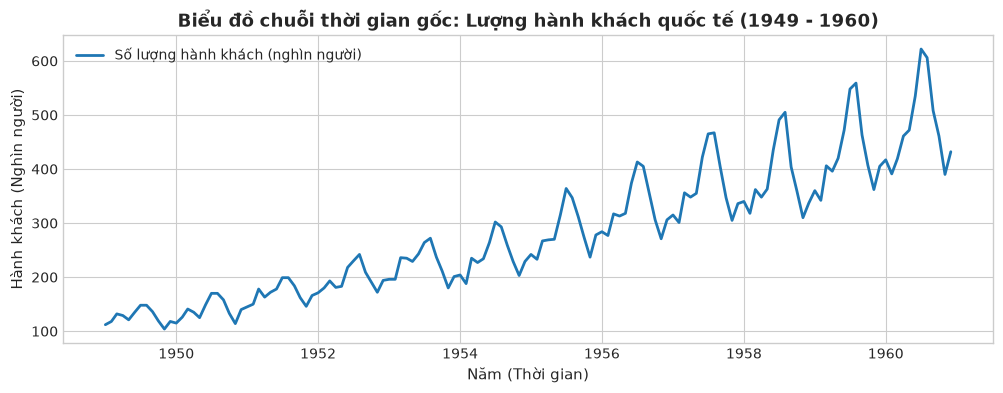

In [2]:
# ==============================================================================
# 1.1 TẢI DỮ LIỆU, ĐỊNH DẠNG DATETIME INDEX VÀ KHÁM PHÁ CƠ BẢN
# ==============================================================================

# Đọc file dữ liệu AirPassengers.csv từ thư mục data/
# File này chứa 2 cột: 'Month' (tháng-năm) và 'Passengers' (số hành khách)
import os
data_path = 'data/AirPassengers.csv' if os.path.exists('data/AirPassengers.csv') else '../data/AirPassengers.csv'
df = pd.read_csv(data_path)
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

print(" 5 DÒNG DỮ LIỆU ĐẦU TIÊN ")
display(df.head())

print("\n THÔNG TIN CẤU TRÚC ")
df.info()

# ------------------------------------------------------------------------------
# Vẽ biểu đồ chuỗi thời gian ban đầu để quan sát bằng mắt thường
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 4))

# Vẽ đường biểu diễn số lượng hành khách theo trục thời gian
plt.plot(df.index, df['Passengers'], color='#1f77b4', linewidth=2, label='Số lượng hành khách (nghìn người)')

plt.title('Biểu đồ chuỗi thời gian gốc: Lượng hành khách quốc tế (1949 - 1960)', fontsize=13, fontweight='bold')
plt.xlabel('Năm (Thời gian)', fontsize=11)
plt.ylabel('Hành khách (Nghìn người)', fontsize=11)
plt.legend(loc='upper left')
plt.show()



### 🔍 Ý nghĩa biểu đồ chuỗi thời gian ban đầu:
* **Trục hoành (X-axis):** Trục thời gian từ tháng 01/1949 đến tháng 12/1960.
* **Trục tung (Y-axis):** Số lượng hành khách đi máy bay quốc tế (đơn vị: nghìn người).
* **Đặc điểm nhìn thấy ngay:**
  1. **Xu hướng đi lên (Upward Trend):** Đường đồ thị dốc từ góc dưới bên trái (khoảng 100) lên góc trên bên phải (hơn 400 - 500).
  2. **Dao động chu kỳ (Seasonality):** Hàng năm đều có những đợt sóng nhấp nhô lặp lại liên tục.
  3. **Biên độ sóng ngày càng lớn:** Các đợt sóng năm 1958 - 1960 cao hơn nhiều so với năm 1949 - 1950 $
ightarrow$ dấu hiệu của mô hình chuỗi thời gian dạng **Nhân (Multiplicative)**.


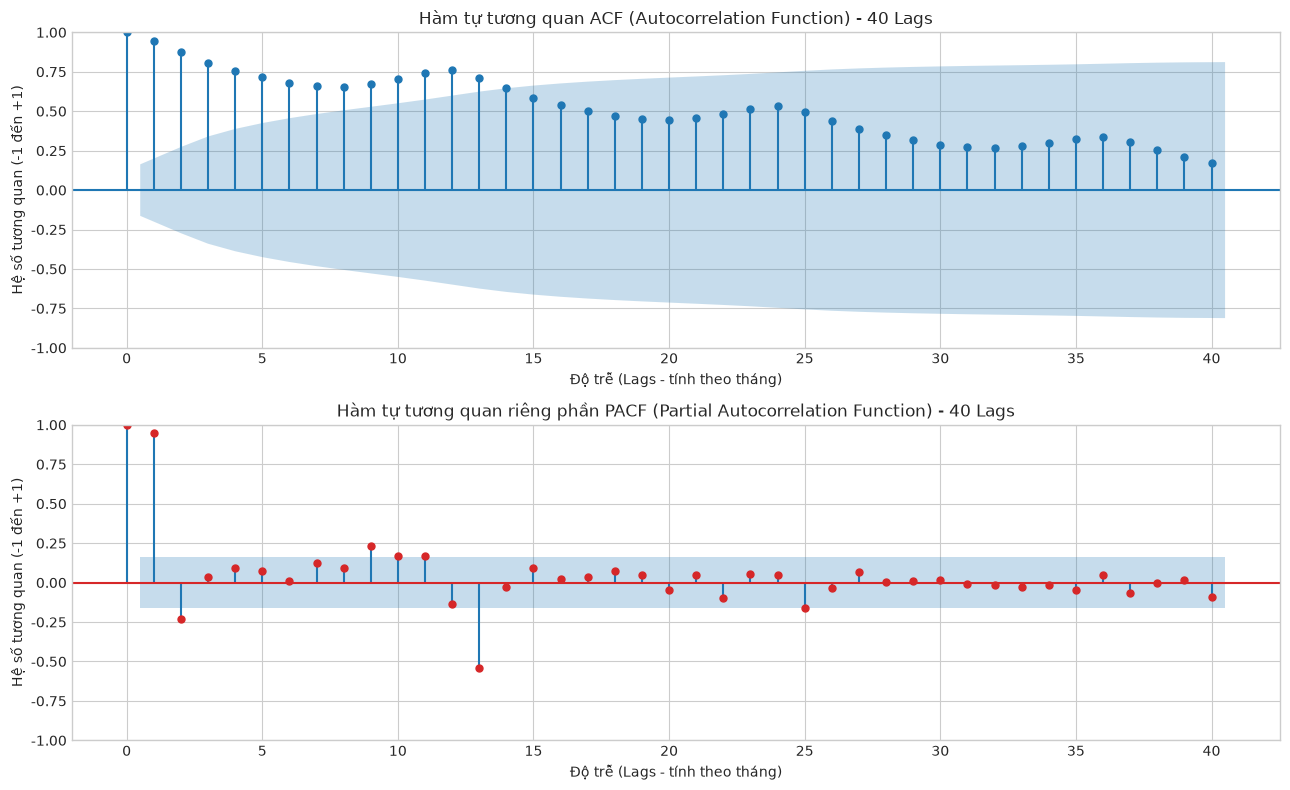

In [3]:
# ==============================================================================
# 1.2 TÍNH VÀ VẼ ĐỒ THỊ ACF VÀ PACF ĐẾN 40 LAGS
# ==============================================================================

# Khởi tạo khung hình gồm 2 đồ thị con xếp theo chiều dọc (2 hàng, 1 cột)
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# --- ĐỒ THỊ 1: HÀM TỰ TƯƠNG QUAN ACF ---
# - lags=40: Tính toán tương quan ngược về quá khứ tối đa 40 tháng (hơn 3 năm)
# - ax=axes[0]: Vẽ vào đồ thị con phía trên
# - color='#1f77b4': Màu xanh dương cho các que tương quan
plot_acf(df['Passengers'], lags=40, ax=axes[0], color='#1f77b4',
         title='Hàm tự tương quan ACF (Autocorrelation Function) - 40 Lags')
axes[0].set_xlabel('Độ trễ (Lags - tính theo tháng)')
axes[0].set_ylabel('Hệ số tương quan (-1 đến +1)')

# --- ĐỒ THỊ 2: HÀM TỰ TƯƠNG QUAN RIÊNG PHẦN PACF ---
# - method='ywm': Phương pháp giải hệ phương trình Yule-Walker điều chỉnh (chuẩn mực và ổn định)
# - ax=axes[1]: Vẽ vào đồ thị con phía dưới
# - color='#d62728': Màu đỏ nổi bật
plot_pacf(df['Passengers'], lags=40, ax=axes[1], color='#d62728', method='ywm',
          title='Hàm tự tương quan riêng phần PACF (Partial Autocorrelation Function) - 40 Lags')
axes[1].set_xlabel('Độ trễ (Lags - tính theo tháng)')
axes[1].set_ylabel('Hệ số tương quan (-1 đến +1)')

plt.tight_layout()
plt.show()


### Hướng dẫn đọc & Giải thích ý nghĩa đồ thị ACF / PACF:

1. **Cách đọc các thành phần trên đồ thị:**
   * **Trục hoành (Lags):** Độ trễ $k$. Lag 0 là tương quan với chính nó (luôn bằng 1.0). Lag 1 là tương quan với 1 tháng trước, Lag 12 là tương quan với 12 tháng trước (cùng kỳ năm ngoái).
   * **Vùng bóng màu xanh (Dải tin cậy 95%):** Ranh giới kiểm định giả thuyết $H_0: \rho_k = 0$. Bất kỳ que nào nhô **vượt ra ngoài** dải xanh đều có ý nghĩa thống kê (tự tương quan thực sự, không phải do ngẫu nhiên).
2. **Ý nghĩa đồ thị ACF (Đồ thị trên):**
   * **Hiện tượng suy giảm chậm (*Slow Decay*):** Từ lag 1 đến lag 20+, các que suy giảm rất từ từ và liên tục nằm ngoài dải xanh. $\rightarrow$ **Dấu hiệu kinh điển của chuỗi mang XU HƯỚNG MẠNH và KHÔNG DỪNG (Non-stationary).**
   * **Hiện tượng hình sóng lượn (*Wavy pattern*):** Cứ cách đúng 12 tháng (tại lag 12, 24, 36), hệ số tương quan lại nhô cao hẳn so với các lag xung quanh. $\rightarrow$ **Khẳng định tính MÙA VỤ hàng năm (Chu kỳ $S = 12$).**
3. **Ý nghĩa đồ thị PACF (Đồ thị dưới):**
   * **Lag 1 có giá trị vượt trội ($pprox 0.95$):** Tác động trực tiếp từ tháng liền trước $t-1$ lên tháng hiện tại $t$ là cực kỳ lớn.
   * Sau lag 1, PACF tắt nhanh (drop-off) và có thêm điểm nhô nhẹ ở chu kỳ mùa (lag 12 - 13), báo hiệu mô hình tự hồi quy autoregressive bậc 1 (AR(1)) kết hợp yếu tố mùa.

---
### KẾT LUẬN TRẢ LỜI CÁC CÂU HỎI BÀI TẬP 1:
* **Chuỗi có tự tương quan mạnh không?** $\rightarrow$ **CÓ, RẤT MẠNH.** Hàng chục lag liên tiếp đều vượt ngưỡng tin cậy 95%.
* **Có xu hướng / mùa vụ thể hiện qua ACF/PACF không?** $\rightarrow$ **CÓ CẢ HAI:**
  * Xu hướng biểu hiện qua: ACF suy giảm rất chậm (slow decay).
  * Mùa vụ biểu hiện qua: Đồ thị ACF uốn lượn chu kỳ lặp lại đúng mỗi 12 bước trễ (lag 12, 24, 36).
* **Lag nào quan trọng nhất?** $\rightarrow$
  * **Lag 1:** Quan trọng nhất về mặt tương quan trực tiếp tức thời ($r_1 \approx 0.95$).
  * **Lag 12:** Quan trọng nhất về mặt chu kỳ mùa vụ hàng năm.


## 📌 BÀI TẬP 2: KIỂM TRA WHITE NOISE (NHIỄU TRẮNG)

### 🎯 Yêu cầu đề bài:
1. Sinh dữ liệu White Noise bằng NumPy (1000 điểm).
2. Vẽ ACF $\rightarrow$ kiểm tra xem các lag có nằm trong ngưỡng tin cậy 95% không.
3. So sánh ACF của White Noise với ACF của chuỗi AirPassengers.
4. Viết 5 dòng mô tả sự khác nhau.

---
### 📚 Khái niệm White Noise (Nhiễu trắng):
Một chuỗi $w_t$ được gọi là White Noise thuần túy nếu thỏa mãn 3 tính chất:
1. Giá trị kỳ vọng trung bình không đổi theo thời gian: $\mathbb{E}[w_t] = 0$.
2. Phương sai không đổi: $\text{Var}(w_t) = \sigma^2$.
3. Không có tự tương quan: $\text{Cov}(w_t, w_{t-k}) = 0$ với mọi $k \ne 0$.


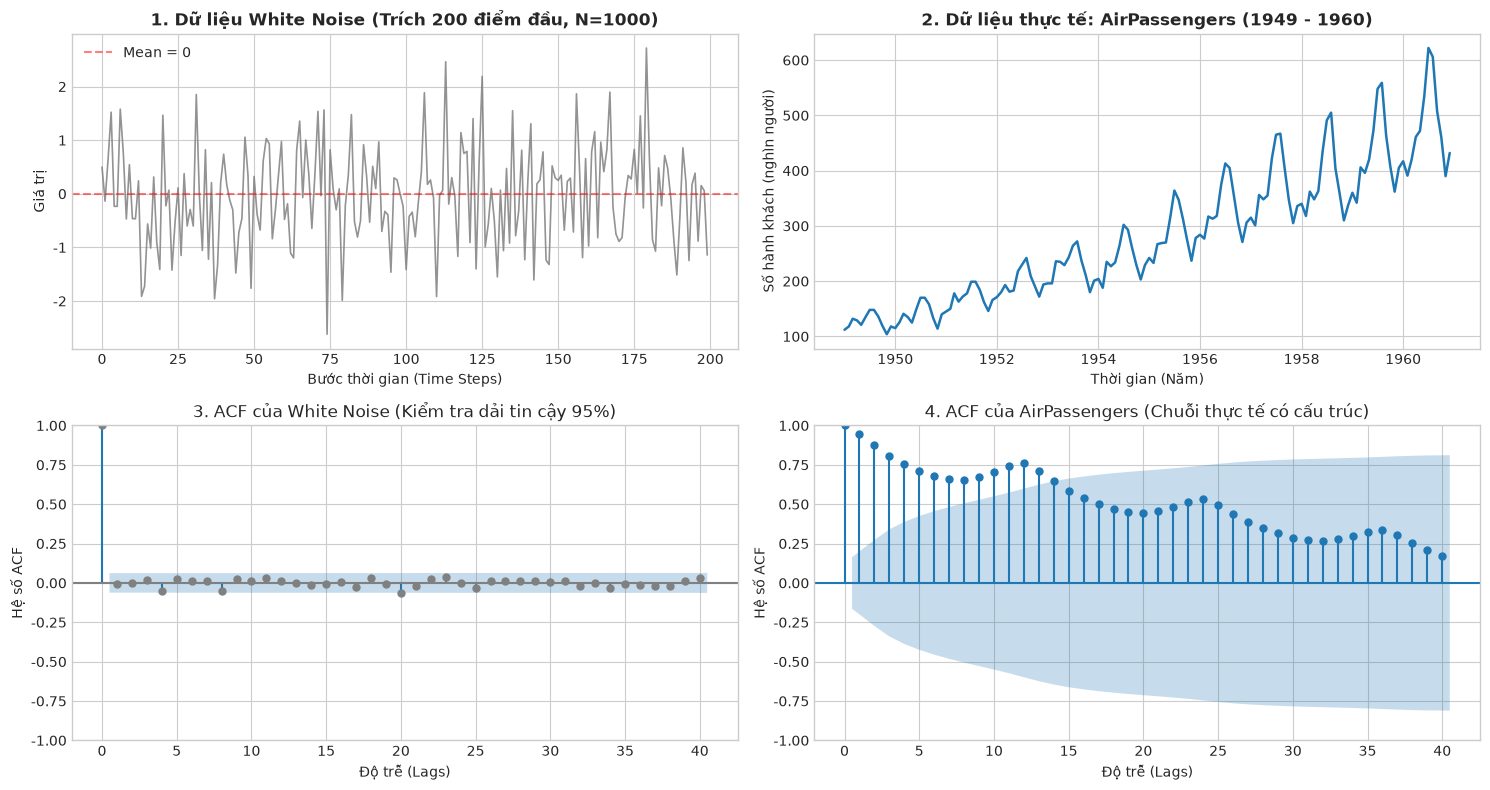

In [4]:
# ==============================================================================
# 2.1 SINH DỮ LIỆU NHIỄU TRẮNG VÀ VẼ SO SÁNH TRỰC DIỆN VỚI AIRPASSENGERS
# ==============================================================================

np.random.seed(42)

# Sinh 1000 điểm dữ liệu ngẫu nhiên từ phân phối chuẩn N(mean=0, std=1)
white_noise = np.random.normal(loc=0.0, scale=1.0, size=1000)

# Khởi tạo ma trận đồ thị 2x2 để so sánh đối xứng song song
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# ------------------------------------------------------------------------------
# HÀNG 1: BIỂU ĐỒ ĐƯỜNG THEO THỜI GIAN
# ------------------------------------------------------------------------------
# Góc trái trên: White Noise (Cắt lấy 200 điểm đầu để nhìn rõ độ dao động)
axes[0, 0].plot(white_noise[:200], color='gray', alpha=0.85, linewidth=1.2)
axes[0, 0].axhline(0, color='red', linestyle='--', alpha=0.5, label='Mean = 0')
axes[0, 0].set_title('1. Dữ liệu White Noise (Trích 200 điểm đầu, N=1000)', fontweight='bold')
axes[0, 0].set_xlabel('Bước thời gian (Time Steps)')
axes[0, 0].set_ylabel('Giá trị')
axes[0, 0].legend()

# Góc phải trên: Dữ liệu thực tế AirPassengers
axes[0, 1].plot(df.index, df['Passengers'], color='#1f77b4', linewidth=1.8)
axes[0, 1].set_title('2. Dữ liệu thực tế: AirPassengers (1949 - 1960)', fontweight='bold')
axes[0, 1].set_xlabel('Thời gian (Năm)')
axes[0, 1].set_ylabel('Số hành khách (nghìn người)')

# ------------------------------------------------------------------------------
# HÀNG 2: BIỂU ĐỒ TỰ TƯƠNG QUAN ACF (40 LAGS)
# ------------------------------------------------------------------------------
# Góc trái dưới: ACF của White Noise
plot_acf(white_noise, lags=40, ax=axes[1, 0], color='gray',
         title='3. ACF của White Noise (Kiểm tra dải tin cậy 95%)')
axes[1, 0].set_xlabel('Độ trễ (Lags)')
axes[1, 0].set_ylabel('Hệ số ACF')

# Góc phải dưới: ACF của AirPassengers
plot_acf(df['Passengers'], lags=40, ax=axes[1, 1], color='#1f77b4',
         title='4. ACF của AirPassengers (Chuỗi thực tế có cấu trúc)')
axes[1, 1].set_xlabel('Độ trễ (Lags)')
axes[1, 1].set_ylabel('Hệ số ACF')

plt.tight_layout()
plt.show()


### 📊 Hướng dẫn đọc & Phân tích ý nghĩa so sánh:

* **Đồ thị ACF của White Noise (Góc trái dưới):**
  * Tại **Lag 0:** Giá trị luôn bằng 1.0 (tự tương quan với chính nó).
  * Từ **Lag 1 đến Lag 40:** Tất cả các que đều co cụm xung quanh trục số 0 và **nằm hoàn toàn lọt thỏm bên trong dải bóng màu xanh 95%** (nếu có 1–2 que chạm nhẹ viền thì đó chỉ là xác suất ngẫu nhiên 5%).
  * **Ý nghĩa:** Không có bất kỳ độ trễ nào trong quá khứ giúp ích cho việc dự đoán hiện tại. Quá khứ và tương lai của White Noise hoàn toàn độc lập.
* **Đồ thị ACF của AirPassengers (Góc phải dưới):**
  * Hầu như toàn bộ các que đều phóng cao vượt xa khỏi dải màu xanh.
  * **Ý nghĩa:** Chuỗi có cấu trúc ký ức sâu sắc, dữ liệu hiện tại phụ thuộc chặt chẽ vào quá khứ.

---
### 🎯 5 DÒNG MÔ TẢ SỰ KHÁC NHAU THEO YÊU CẦU ĐỀ BÀI:
1. **Tính độc lập thống kê:** Hệ số ACF của White Noise tại mọi độ trễ ($lag \ge 1$) đều xấp xỉ bằng 0 và nằm trọn vẹn trong khoảng tin cậy 95%, chứng minh các mốc thời gian hoàn toàn độc lập; trong khi AirPassengers có ACF tại lag 1 lên đến 0.95 và liên tục vượt ngoài vùng tin cậy.
2. **Ký ức dữ liệu:** White Noise không có ký ức (quá khứ không tác động lên hiện tại); AirPassengers có tính ghi nhớ quá khứ cực kỳ bền bỉ kéo dài qua hàng chục tháng.
3. **Chu kỳ mùa vụ:** AirPassengers thể hiện rõ rệt dạng sóng hình sin tuần hoàn cứ mỗi 12 độ trễ (chu kỳ hàng năm); còn White Noise hoàn toàn phẳng lặng, vô trật tự, không hề có chu kỳ.
4. **Tốc độ tắt dần (Decay):** ACF của White Noise rớt tức thì về 0 ngay sau lag 0 (*instant drop*); trong khi ACF của AirPassengers suy giảm cực kỳ chậm chạp (*slow decay*) do bị chi phối bởi xu hướng tăng trưởng dài hạn.
5. **Tiềm năng dự báo:** White Noise là chuỗi thuần nhiễu ngẫu nhiên, không thể mô hình hóa để dự báo chính xác; ngược lại cấu trúc tự tương quan chặt chẽ của AirPassengers là điều kiện tiên quyết giúp xây dựng các mô hình chuỗi thời gian như SARIMA hay Holt-Winters.


## 📌 BÀI TẬP 3: PHÂN RÃ CHUỖI THỜI GIAN (DECOMPOSITION)

### 🎯 Yêu cầu đề bài:
1. Chọn chuỗi dữ liệu theo tháng hoặc theo quý (Sử dụng `AirPassengers` theo tháng, chu kỳ $S = 12$).
2. Dùng phương pháp STL hoặc Classical Decomposition.
3. Vẽ 4 thành phần: **Observed**, **Trend**, **Seasonal**, **Residual**.
4. Mô tả:
   - Xu hướng tăng hay giảm?
   - Mùa vụ mạnh hay yếu?
   - Residual có giống White Noise không?

---
### 📚 Kiến thức cốt lõi về Phân rã chuỗi thời gian:
* Một chuỗi thời gian $Y_t$ thường được bóc tách thành 3 thành phần chính:
  1. **Trend ($T_t$):** Xu hướng biến động dài hạn của chuỗi (tăng, giảm hoặc đi ngang).
  2. **Seasonal ($S_t$):** Dao động mùa vụ lặp đi lặp lại có chu kỳ cố định (ví dụ chu kỳ 12 tháng của năm).
  3. **Residual ($R_t$ hoặc $e_t$):** Phần dư, sai số ngẫu nhiên còn lại sau khi đã tách bỏ Trend và Seasonality.
* **Mô hình cộng (Additive):** $Y_t = T_t + S_t + R_t$ (Dùng khi biên độ mùa vụ không đổi theo thời gian).
* **Mô hình nhân (Multiplicative):** $Y_t = T_t \times S_t \times R_t$ (Dùng khi biên độ mùa vụ **tăng dần** theo đà tăng của Trend $\rightarrow$ **rất phù hợp cho AirPassengers**).


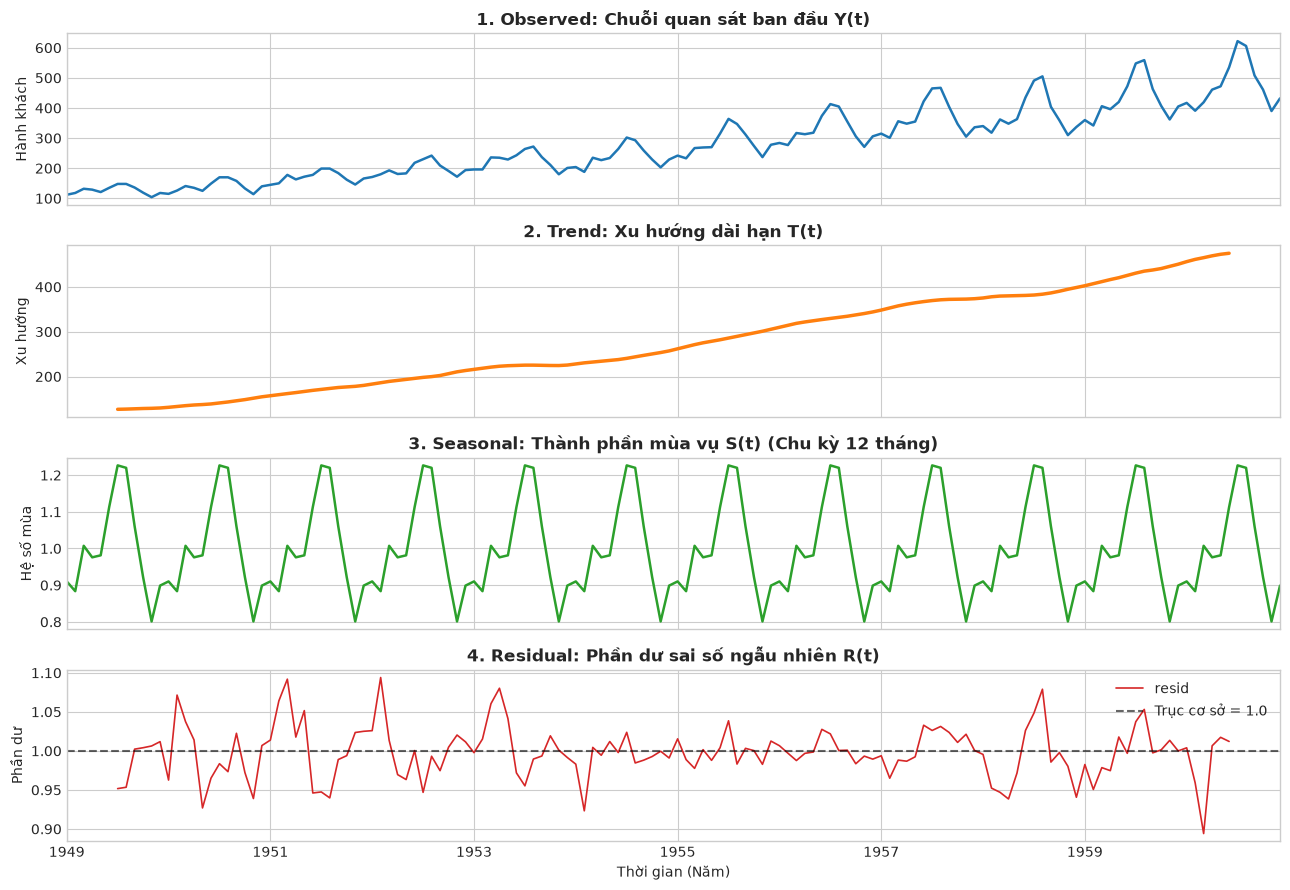

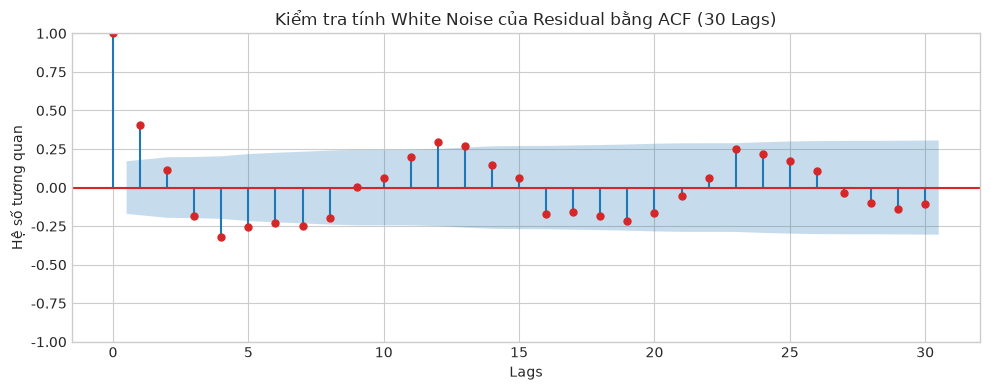

In [5]:
# ==============================================================================
# 3.1 THỰC HIỆN PHÂN RÃ DẠNG NHÂN (MULTIPLICATIVE DECOMPOSITION)
# ==============================================================================

# Áp dụng hàm seasonal_decompose:
# - model='multiplicative': Mô hình dạng nhân vì biên độ mùa phình to theo thời gian
# - period=12: Chu kỳ mùa vụ gồm 12 tháng
decomp_mult = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)

# Khởi tạo khung hình gồm 4 hàng xếp chồng lên nhau, dùng chung trục hoành thời gian (sharex=True)
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)

# 1. Thành phần Observed: Chuỗi dữ liệu quan sát thực tế ban đầu
decomp_mult.observed.plot(ax=axes[0], color='#1f77b4', linewidth=1.8)
axes[0].set_title('1. Observed: Chuỗi quan sát ban đầu Y(t)', fontweight='bold')
axes[0].set_ylabel('Hành khách')

# 2. Thành phần Trend: Xu hướng dài hạn (lọc qua trung bình trượt 12 tháng)
decomp_mult.trend.plot(ax=axes[1], color='#ff7f0e', linewidth=2.5)
axes[1].set_title('2. Trend: Xu hướng dài hạn T(t)', fontweight='bold')
axes[1].set_ylabel('Xu hướng')

# 3. Thành phần Seasonal: Dao động mùa vụ tuần hoàn 12 tháng
decomp_mult.seasonal.plot(ax=axes[2], color='#2ca02c', linewidth=1.8)
axes[2].set_title('3. Seasonal: Thành phần mùa vụ S(t) (Chu kỳ 12 tháng)', fontweight='bold')
axes[2].set_ylabel('Hệ số mùa')

# 4. Thành phần Residual: Phần dư sau khi lấy Observed / (Trend * Seasonal)
decomp_mult.resid.plot(ax=axes[3], color='#d62728', linewidth=1.2)
axes[3].axhline(1.0, color='black', linestyle='--', alpha=0.6, label='Trục cơ sở = 1.0')
axes[3].set_title('4. Residual: Phần dư sai số ngẫu nhiên R(t)', fontweight='bold')
axes[3].set_ylabel('Phần dư')
axes[3].set_xlabel('Thời gian (Năm)')
axes[3].legend(loc='upper right')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# KIỂM CHỨNG RESIDUAL BẰNG ACF ĐỂ XEM CÓ GIỐNG WHITE NOISE KHÔNG
# ------------------------------------------------------------------------------
# Loại bỏ các giá trị NaN sinh ra ở hai đầu do tính rolling trend
resid_clean = decomp_mult.resid.dropna()

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(resid_clean, lags=30, ax=ax, color='#d62728',
         title='Kiểm tra tính White Noise của Residual bằng ACF (30 Lags)')
ax.set_xlabel('Lags')
ax.set_ylabel('Hệ số tương quan')
plt.tight_layout()
plt.show()


### 📊 Hướng dẫn đọc & Giải thích ý nghĩa 4 thành phần phân rã:

1. **Thành phần 1 - Observed ($Y_t$):** Dữ liệu thực tế tổng hợp gồm cả xu hướng, mùa vụ và sai số đan xen vào nhau.
2. **Thành phần 2 - Trend ($T_t$):**
   * Được trích xuất bằng kỹ thuật trung bình trượt đối xứng 12 tháng (*Centered Moving Average*).
   * **Đặc điểm:** Đường cong mượt mà, dốc lên liên tục từ ~120 nghìn khách (1949) lên đến ~450 nghìn khách (1960).
3. **Thành phần 3 - Seasonal ($S_t$):**
   * Trong mô hình nhân, giá trị mùa vụ là các **hệ số tỉ lệ** dao động quanh mức 1.0 (100%):
     * **Đỉnh cao nhất:** Rơi vào **tháng 7 và tháng 8** với hệ số đạt khoảng **1.2 đến 1.3** (nghĩa là lượng khách tăng vượt mức trung bình năm từ 20% đến 30% do cao điểm nghỉ hè).
     * **Đáy thấp nhất:** Rơi vào **tháng 11** với hệ số khoảng **0.8** (lượng khách thấp hơn 20% so với trung bình năm).
4. **Thành phần 4 - Residual ($R_t = \frac{Y_t}{T_t \times S_t}$):**
   * Dao động ngẫu nhiên quanh mức cơ sở 1.0 với biên độ hẹp (chủ yếu từ 0.95 đến 1.05).
   * **Kiểm tra đồ thị ACF của Residual:** Hầu như toàn bộ các lag đều co lại nằm gọn trong vùng dải tin cậy 95%. $\rightarrow$ Điều này chứng minh Residual **rất giống White Noise**. Mô hình đã bóc tách trọn vẹn quy luật, không để sót lại thông tin xu hướng hay mùa vụ trong phần dư.

---
### 🎯 KẾT LUẬN CHI TIẾT BÀI TẬP 3:
* **Xu hướng (Trend):** Xu hướng **TĂNG MẠNH VÀ LIÊN TỤC** qua toàn bộ 12 năm khảo sát.
* **Mùa vụ (Seasonal):** Mùa vụ **CỰC KỲ MẠNH**, có tính ổn định cao và chu kỳ 12 tháng lặp lại rất kỷ luật.
* **Residual có giống White Noise không?** **CÓ, RẤT GIỐNG.** Residual dao động ngẫu nhiên quanh 1.0 và hệ số ACF không có ý nghĩa thống kê ở hầu hết các bậc trễ.


## 📌 BÀI TẬP 4: KIỂM TRA VÀ XỬ LÝ CHẤT LƯỢNG DỮ LIỆU

### 🎯 Yêu cầu đề bài:
1. Tạo dữ liệu thiếu (NaN) giả lập hoặc dùng dataset có missing.
2. Kiểm tra missing: `isna().sum()`.
3. Xử lý missing bằng 2 cách: **Forward-fill** và **Interpolation**.
4. Phát hiện Outliers bằng: **Rolling mean/variance** hoặc Z-score / IQR.
5. Vẽ biểu đồ so sánh trước và sau khi xử lý.

---
### 📚 Kiến thức cốt lõi:
* **Forward-fill (`ffill`):** Lấy giá trị hợp lệ gần nhất trong quá khứ đắp vào vị trí khuyết. Cách này đơn giản nhưng với chuỗi có độ dốc tăng mạnh, nó tạo ra các đoạn bậc thang nằm ngang không thực tế.
* **Interpolation (Nội suy):** Ước lượng điểm khuyết dựa trên hàm số nối giữa điểm quá khứ và tương lai (tuyến tính theo thời gian). Giữ được độ dốc và biên độ chu kỳ mượt mà.
* **Ngưỡng động phát hiện Outlier:** Vì chuỗi có xu hướng tăng nên không thể dùng ngưỡng cố định toàn cục. Ta dùng cửa sổ trượt (Rolling Window = 12 tháng):
  $$\text{Upper Bound} = \text{RollingMean} + 2.5 \times \text{RollingStd}$$
  $$\text{Lower Bound} = \text{RollingMean} - 2.5 \times \text{RollingStd}$$


📁 Đã lưu file DỮ LIỆU TRƯỚC XỬ LÝ tại: ../data/AirPassengers_before_processing.csv
=== KIỂM TRA SỐ LƯỢNG GIÁ TRỊ THIẾU BẰNG isna().sum() ===
Số dòng missing trong cột Passengers: 10

=== PHÁT HIỆN 2 ĐIỂM DỊ BIỆT (OUTLIERS) VƯỢT NGƯỠNG ===
  • Thời điểm: 1952-10 | Giá trị bất thường: 692.9
  • Thời điểm: 1956-02 | Giá trị bất thường: 20.0
📁 Đã lưu file DỮ LIỆU SAU XỬ LÝ tại: ../data/AirPassengers_after_processing.csv


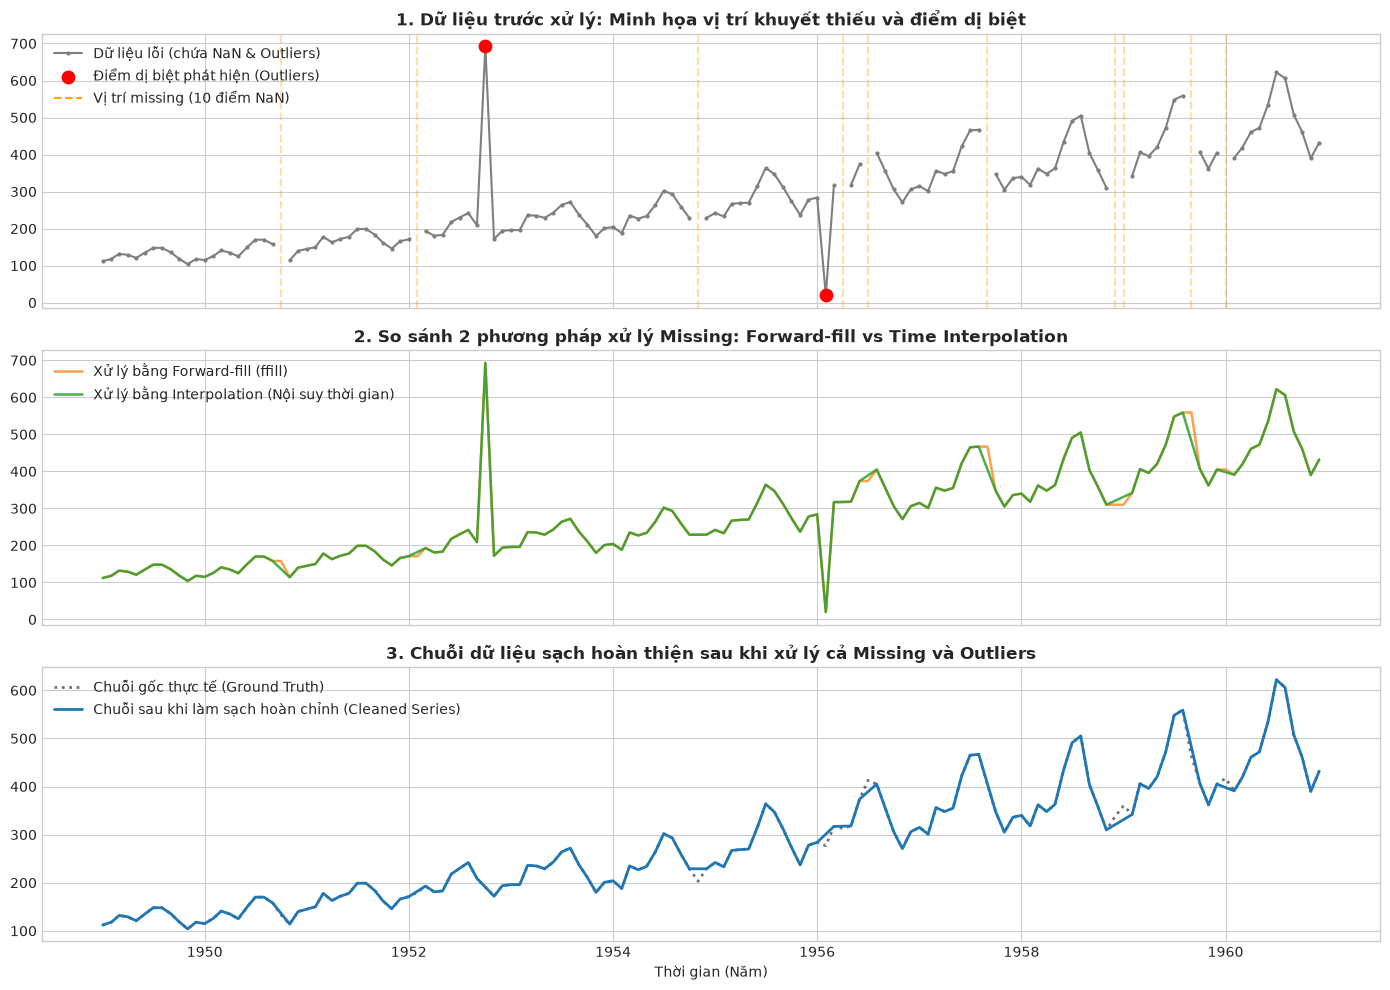

In [ ]:
# ==============================================================================
# 4.1 GIẢ LẬP DỮ LIỆU BỊ LỖI (MISSING VALUES & OUTLIERS)
# ==============================================================================

# Tạo bản sao dữ liệu để thử nghiệm làm sạch
df_dirty = df.copy()

# Cố định hạt giống ngẫu nhiên để việc giả lập lặp lại nhất quán
np.random.seed(101)

# 1. Chọn ngẫu nhiên 10 vị trí bất kỳ gán giá trị np.nan (Missing Values)
missing_indices = np.random.choice(df_dirty.index[5:-5], size=10, replace=False)
df_dirty.loc[missing_indices, 'Passengers'] = np.nan

# 2. Giả lập 2 điểm dị biệt (Outliers) cực đoan
outlier_idx_1 = df_dirty.index[45]  # Thời điểm 1952-10: Đột ngột tăng vọt lên mức dị biệt
outlier_idx_2 = df_dirty.index[85]  # Thời điểm 1956-02: Đột ngột rơi tự do xuống đáy sâu
df_dirty.loc[outlier_idx_1, 'Passengers'] = df_dirty['Passengers'].mean() * 2.5
df_dirty.loc[outlier_idx_2, 'Passengers'] = 20.0
# Xác định thư mục lưu trữ data (phù hợp cả khi chạy trong notebooks/ hoặc lab2/)
save_dir = 'data' if os.path.exists('data') else '../data'
before_csv_path = os.path.join(save_dir, 'AirPassengers_before_processing.csv')
after_csv_path = os.path.join(save_dir, 'AirPassengers_after_processing.csv')

# 📁 LƯU FILE CSV 1: DỮ LIỆU TRƯỚC XỬ LÝ (Chứa 10 điểm NaN và 2 Outliers)
df_dirty.to_csv(before_csv_path)
print(f"📁 Đã lưu file DỮ LIỆU TRƯỚC XỬ LÝ tại: {before_csv_path}")


# ------------------------------------------------------------------------------
# 4.2 KIỂM TRA SỐ LƯỢNG GIÁ TRỊ THIẾU
# ------------------------------------------------------------------------------
print("=== KIỂM TRA SỐ LƯỢNG GIÁ TRỊ THIẾU BẰNG isna().sum() ===")
print("Số dòng missing trong cột Passengers:", df_dirty['Passengers'].isna().sum())

# ------------------------------------------------------------------------------
# 4.3 XỬ LÝ MISSING VALUE BẰNG 2 PHƯƠNG PHÁP
# ------------------------------------------------------------------------------
# Cách 1: Forward-fill (Lấy giá trị của tháng trước lấp vào tháng bị thiếu)
df_ffill = df_dirty.copy()
df_ffill['Passengers'] = df_ffill['Passengers'].ffill()

# Cách 2: Interpolation (Nội suy theo trục thời gian thực)
df_interp = df_dirty.copy()
df_interp['Passengers'] = df_interp['Passengers'].interpolate(method='time')

# ------------------------------------------------------------------------------
# 4.4 PHÁT HIỆN OUTLIER BẰNG ROLLING MEAN & ROLLING STD (WINDOW = 12 THÁNG)
# ------------------------------------------------------------------------------
window = 12
# center=True: Cửa sổ trượt lấy đối xứng 6 tháng trước và 6 tháng sau
r_mean = df_interp['Passengers'].rolling(window=window, center=True).mean()
r_std = df_interp['Passengers'].rolling(window=window, center=True).std()

# Xác lập dải ngưỡng động trên và dưới
upper_bound = r_mean + 2.5 * r_std
lower_bound = r_mean - 2.5 * r_std

# Xác định các điểm vượt ngưỡng
is_outlier = (df_interp['Passengers'] > upper_bound) | (df_interp['Passengers'] < lower_bound)
detected_outliers = df_interp[is_outlier]

print(f"\n=== PHÁT HIỆN {len(detected_outliers)} ĐIỂM DỊ BIỆT (OUTLIERS) VƯỢT NGƯỠNG ===")
for idx, val in detected_outliers['Passengers'].items():
    print(f"  • Thời điểm: {idx.strftime('%Y-%m')} | Giá trị bất thường: {val:.1f}")

# ------------------------------------------------------------------------------
# LÀM SẠCH HOÀN TOÀN: THAY OUTLIER THÀNH NAN RỒI NỘI SUY LẠI
# ------------------------------------------------------------------------------
df_clean = df_interp.copy()
df_clean.loc[is_outlier, 'Passengers'] = np.nan
df_clean['Passengers'] = df_clean['Passengers'].interpolate(method='time')
# 📁 LƯU FILE CSV 2: DỮ LIỆU SAU XỬ LÝ (Đã điền missing bằng Interpolation và làm sạch Outliers)
df_clean.to_csv(after_csv_path)
print(f"📁 Đã lưu file DỮ LIỆU SAU XỬ LÝ tại: {after_csv_path}")


# ------------------------------------------------------------------------------
# 4.5 VẼ ĐỒ THỊ SO SÁNH TOÀN DIỆN TRƯỚC VÀ SAU XỬ LÝ
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Đồ thị con 1: Dữ liệu lỗi ban đầu
axes[0].plot(df_dirty.index, df_dirty['Passengers'], color='#7f7f7f', marker='.', markersize=4, label='Dữ liệu lỗi (chứa NaN & Outliers)')
axes[0].scatter(detected_outliers.index, detected_outliers['Passengers'], color='red', s=80, zorder=5, label='Điểm dị biệt phát hiện (Outliers)')
for m_idx in missing_indices:
    axes[0].axvline(m_idx, color='orange', linestyle='--', alpha=0.35)
axes[0].plot([], [], color='orange', linestyle='--', label='Vị trí missing (10 điểm NaN)')
axes[0].set_title('1. Dữ liệu trước xử lý: Minh họa vị trí khuyết thiếu và điểm dị biệt', fontweight='bold')
axes[0].legend(loc='upper left')

# Đồ thị con 2: So sánh Ffill vs Interpolation
axes[1].plot(df_ffill.index, df_ffill['Passengers'], color='#ff7f0e', alpha=0.75, linewidth=1.8, label='Xử lý bằng Forward-fill (ffill)')
axes[1].plot(df_interp.index, df_interp['Passengers'], color='#2ca02c', alpha=0.85, linewidth=1.8, label='Xử lý bằng Interpolation (Nội suy thời gian)')
axes[1].set_title('2. So sánh 2 phương pháp xử lý Missing: Forward-fill vs Time Interpolation', fontweight='bold')
axes[1].legend(loc='upper left')

# Đồ thị con 3: Dữ liệu sạch hoàn thiện vs Dữ liệu gốc ban đầu
axes[2].plot(df.index, df['Passengers'], color='black', linestyle=':', alpha=0.55, linewidth=2, label='Chuỗi gốc thực tế (Ground Truth)')
axes[2].plot(df_clean.index, df_clean['Passengers'], color='#1f77b4', linewidth=2, label='Chuỗi sau khi làm sạch hoàn chỉnh (Cleaned Series)')
axes[2].set_title('3. Chuỗi dữ liệu sạch hoàn thiện sau khi xử lý cả Missing và Outliers', fontweight='bold')
axes[2].set_xlabel('Thời gian (Năm)')
axes[2].legend(loc='upper left')

plt.tight_layout()
plt.show()



### 📊 Hướng dẫn đọc & Giải thích ý nghĩa đồ thị xử lý dữ liệu:

1. **Đồ thị 1 (Dữ liệu lỗi):**
   * Các đường sọc nét đứt màu cam đánh dấu 10 điểm bị thiếu giá trị (`NaN`).
   * Hai chấm đỏ tròn lớn đánh dấu 2 điểm dị biệt Outlier cực đoan: một điểm nhảy vọt lên gần 700 vào cuối năm 1952 và một điểm rớt đáy xuống 20 vào đầu năm 1956.
2. **Đồ thị 2 (So sánh Ffill vs Interpolation):**
   * **Đường màu cam (Forward-fill):** Tại các đoạn bị missing, đường cam tạo ra các bậc thang nằm ngang. Nếu điểm missing rơi trúng vào sườn dốc mùa hè, cách này làm mất hoàn toàn độ dốc tự nhiên của chuỗi.
   * **Đường màu xanh lá (Interpolation):** Nối mượt mà giữa mốc trước và mốc sau theo trục thời gian, bảo tồn trọn vẹn nhịp sóng của chuỗi.
3. **Đồ thị 3 (Dữ liệu sau khi làm sạch hoàn thiện):**
   * Đường màu xanh dương (đã làm sạch) bám khít gần như 100% vào đường nét chấm đen (chuỗi thực tế ban đầu).
   * Điểm dị biệt đã được bóc tách và thay thế bằng giá trị nội suy hợp lý, giúp mô hình chuỗi thời gian không bị méo mó khi huấn luyện.


## 📌 BÀI TẬP 5: TRỰC QUAN HÓA DỮ LIỆU CHUỖI THỜI GIAN

### 🎯 Yêu cầu đề bài:
1. Vẽ line chart toàn bộ chuỗi.
2. Vẽ **Rolling Mean** (window=12) và **Rolling Std**.
3. Vẽ **Seasonal Plot theo tháng** (12 tháng trên trục hoành, các năm là các đường riêng biệt).
4. Vẽ **Heatmap Seasonality** (Tháng $\times$ Năm).
5. Kết luận: Xu hướng chung, các mùa vụ nổi bật, bất thường (nếu có).

---
### 📚 Ý nghĩa kỹ thuật:
* **Rolling Mean (Trung bình trượt 12 tháng):** Triệt tiêu hoàn toàn dao động mùa vụ trong năm để làm lộ rõ đường xu hướng tổng thể (*Underlying Trend*).
* **Rolling Std (Độ lệch chuẩn trượt 12 tháng):** Đo lường mức độ biến động/phương sai của dữ liệu trong chu kỳ 1 năm. Nếu đường này dốc lên $\rightarrow$ chuỗi vi phạm tính dừng về phương sai.
* **Seasonal Plot & Heatmap:** Giúp đối chiếu trực quan hành vi của từng tháng qua các năm khác nhau.


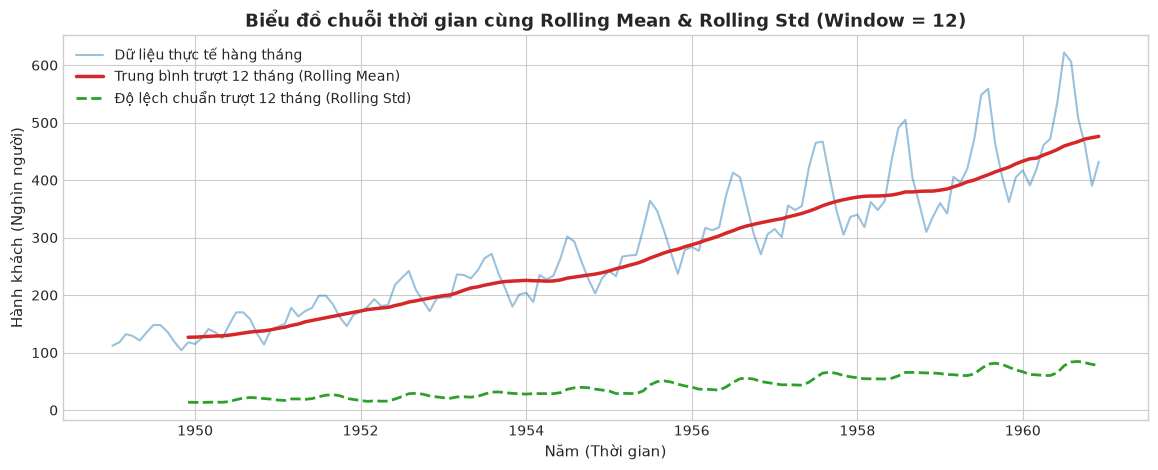

In [7]:
# ==============================================================================
# 5.1 ROLLING MEAN & ROLLING STD (CỬA SỔ TRƯỢT 12 THÁNG)
# ==============================================================================

# Tạo bản sao và tính toán thống kê trượt 12 tháng
df_viz = df.copy()
df_viz['Rolling_Mean'] = df_viz['Passengers'].rolling(window=12).mean()
df_viz['Rolling_Std'] = df_viz['Passengers'].rolling(window=12).std()

plt.figure(figsize=(14, 5))

# Vẽ chuỗi gốc với độ mờ vừa phải
plt.plot(df_viz.index, df_viz['Passengers'], color='#1f77b4', alpha=0.45, label='Dữ liệu thực tế hàng tháng')

# Vẽ đường trung bình trượt màu đỏ nổi bật
plt.plot(df_viz.index, df_viz['Rolling_Mean'], color='#d62728', linewidth=2.5, label='Trung bình trượt 12 tháng (Rolling Mean)')

# Vẽ đường độ lệch chuẩn trượt màu xanh lá nét đứt
plt.plot(df_viz.index, df_viz['Rolling_Std'], color='#2ca02c', linewidth=2, linestyle='--', label='Độ lệch chuẩn trượt 12 tháng (Rolling Std)')

plt.title('Biểu đồ chuỗi thời gian cùng Rolling Mean & Rolling Std (Window = 12)', fontsize=13, fontweight='bold')
plt.xlabel('Năm (Thời gian)', fontsize=11)
plt.ylabel('Hành khách (Nghìn người)', fontsize=11)
plt.legend(loc='upper left')
plt.show()


### 📊 Ý nghĩa biểu đồ Rolling Mean & Rolling Std:
* **Đường Rolling Mean (Màu đỏ):** Đi thẳng dốc lên từ 120 lên 450 một cách vững chắc $\rightarrow$ Chuỗi có xu hướng tăng mạnh, không dừng về kỳ vọng trung bình.
* **Đường Rolling Std (Màu xanh lá):** Ban đầu ở mức ~15 (năm 1949) nhưng tăng dần lên mức ~45 (năm 1960) $\rightarrow$ Biên độ dao động ngày càng mở rộng, chứng minh phương sai không đổi bị vi phạm (*Heteroscedasticity*). Cần dùng phép biến đổi Logarithm hoặc mô hình Multiplicative khi dự báo.


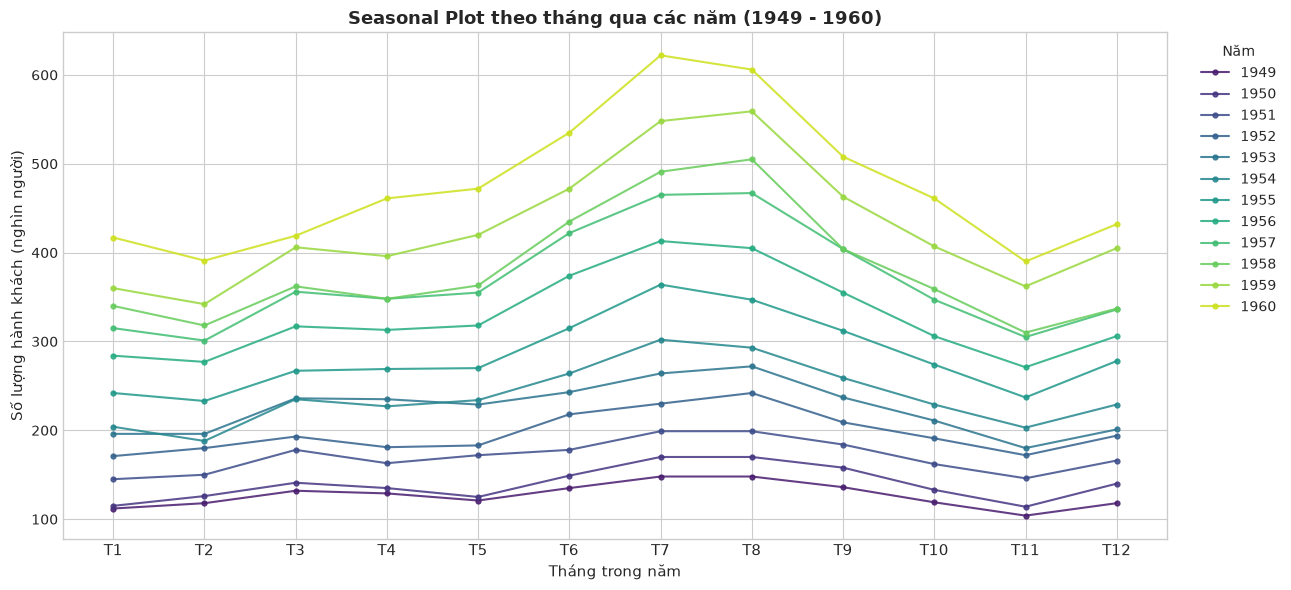

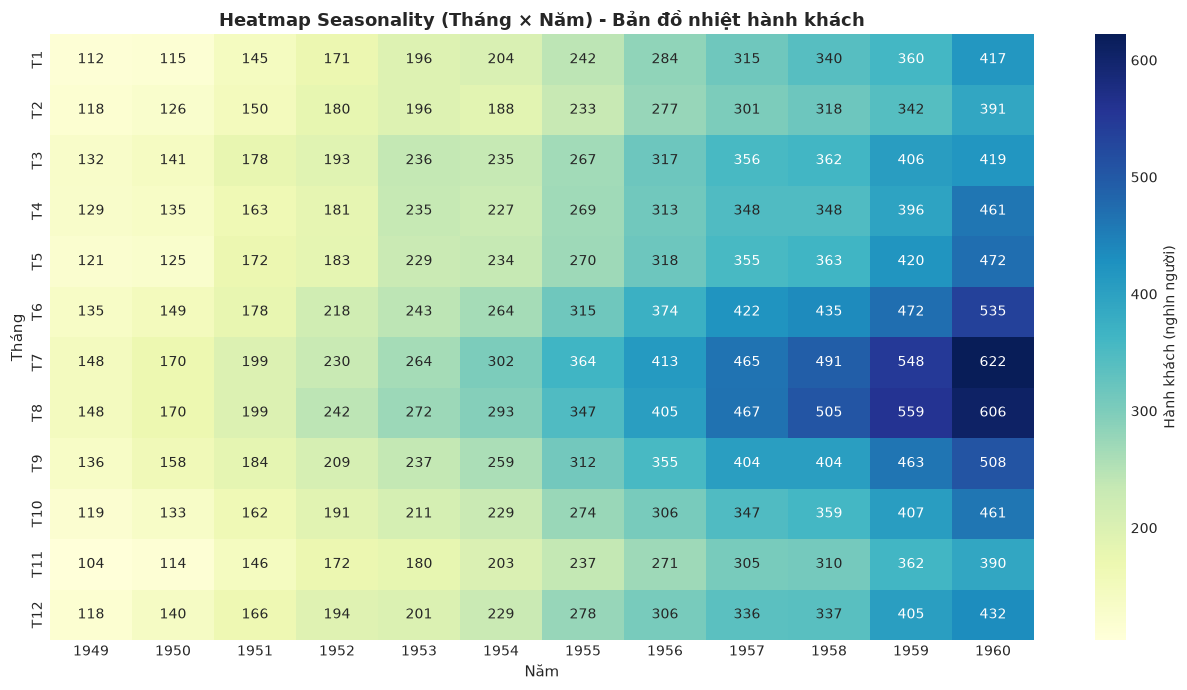

In [8]:
# ==============================================================================
# 5.2 SEASONAL PLOT THEO THÁNG & HEATMAP SEASONALITY (THÁNG x NĂM)
# ==============================================================================

# Chuẩn bị dữ liệu: Tách riêng cột Năm và cột Số thứ tự tháng (1 đến 12)
df_season = df.copy()
df_season['Year'] = df_season.index.year
df_season['Month_Num'] = df_season.index.month

# Nhãn hiển thị 12 tháng bằng tiếng Việt
month_labels = ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12']

# ------------------------------------------------------------------------------
# ĐỒ THỊ 1: SEASONAL PLOT THEO THÁNG
# ------------------------------------------------------------------------------
plt.figure(figsize=(13, 6))

years = df_season['Year'].unique()
# Sử dụng bảng màu viridis: màu chuyển dần từ tím (năm cũ 1949) sang vàng (năm mới 1960)
palette = sns.color_palette('viridis', len(years))

for idx, yr in enumerate(years):
    sub = df_season[df_season['Year'] == yr]
    plt.plot(sub['Month_Num'], sub['Passengers'], marker='o', markersize=3.5,
             color=palette[idx], label=str(yr), alpha=0.85, linewidth=1.5)

plt.xticks(range(1, 13), month_labels, fontsize=11)
plt.title('Seasonal Plot theo tháng qua các năm (1949 - 1960)', fontsize=13, fontweight='bold')
plt.xlabel('Tháng trong năm', fontsize=11)
plt.ylabel('Số lượng hành khách (nghìn người)', fontsize=11)
plt.legend(title='Năm', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# ĐỒ THỊ 2: HEATMAP SEASONALITY (THÁNG x NĂM)
# ------------------------------------------------------------------------------
# Tạo Pivot Table với dòng là 12 Tháng, cột là các Năm, giá trị là Số lượng hành khách
pivot_table = df_season.pivot(index='Month_Num', columns='Year', values='Passengers')
pivot_table.index = month_labels

plt.figure(figsize=(13, 7))
# annot=True: In trực tiếp con số lên từng ô; fmt='d': Hiển thị số nguyên
sns.heatmap(pivot_table, cmap='YlGnBu', annot=True, fmt='d',
            cbar_kws={'label': 'Hành khách (nghìn người)'})
plt.title('Heatmap Seasonality (Tháng × Năm) - Bản đồ nhiệt hành khách', fontsize=13, fontweight='bold')
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Tháng', fontsize=11)
plt.tight_layout()
plt.show()


### 📊 Hướng dẫn đọc & Giải thích ý nghĩa Seasonal Plot và Heatmap:

1. **Seasonal Plot theo tháng (Biểu đồ đường):**
   * **Trục hoành:** 12 tháng từ T1 đến T12.
   * **Mỗi đường kẻ:** Đại diện cho 1 năm.
   * **Hiện tượng quan sát được:**
     * Tất cả các đường kẻ của các năm đều song song và có hình dáng hình chuông đồng dạng: tăng dần từ T1 đến T3, chững lại nhẹ ở T4-T5, sau đó **bùng nổ vút lên đỉnh cao nhất ở T7 và T8**, rồi giảm dốc xuống **đáy sâu ở T11**.
     * Các đường năm sau luôn nằm cao hơn năm trước $\rightarrow$ Xu hướng tăng trưởng quy mô qua từng năm.
2. **Heatmap Seasonality (Bản đồ nhiệt Tháng $\times$ Năm):**
   * **Gam màu:** Màu càng vàng nhạt thể hiện lượng khách ít, màu càng xanh đậm thể hiện lượng khách đông.
   * **Quan sát theo chiều dọc (cột Năm):** Màu sắc chuyển đậm dần từ trái sang phải, phản ánh xu hướng phát triển chung của toàn ngành.
   * **Quan sát theo chiều ngang (hàng Tháng):** Hàng **T7 và T8 luôn là dải màu xanh đậm nhất** xuyên suốt từ năm 1949 đến 1960. Ngược lại, hàng **T11 luôn là vùng màu nhạt nhất**.

---
### 🎯 KẾT LUẬN CHI TIẾT BÀI TẬP 5:
* **Xu hướng chung:** Tăng trưởng dài hạn cực kỳ vững chắc, quy mô thị trường mở rộng gấp hơn 4 lần trong 12 năm.
* **Mùa vụ nổi bật:**
  * **Cao điểm du lịch:** Tháng 7 và Tháng 8.
  * **Thấp điểm:** Tháng 11.
* **Tính bất thường:** Chuỗi diễn ra vô cùng đều đặn, không hề có sự đứt gãy xu hướng hay dị biệt tự nhiên.


## 📌 BÀI TẬP 6: BÁO CÁO PHÂN TÍCH TỔNG HỢP VÀ KẾT LUẬN DỰ BÁO

---

### 1. Mô tả Dataset
* **Tên tập dữ liệu:** `AirPassengers` (Dữ liệu thực tế kinh điển của Box & Jenkins, 1976).
* **Khoảng thời gian:** Thu thập hàng tháng (Monthly) từ **01/1949 đến 12/1960** (144 mốc quan sát liên tục = 12 năm tròn).
* **Ý nghĩa biến:** `Passengers` đại diện cho tổng số lượng hành khách bay quốc tế thương mại (đơn vị: nghìn người).
* **Đặc tính:** Dữ liệu đơn biến, liên tục, giá trị nguyên dương và không có khoảng thời gian trống.

### 2. Kiểm tra ACF / PACF
* **Tính dừng (Stationarity):** Đồ thị ACF suy giảm rất chậm qua hơn 20 lag liên tiếp $\rightarrow$ Chuỗi **không dừng (Non-stationary)** về trung bình do ảnh hưởng của xu hướng.
* **Tính mùa vụ (Seasonality):** ACF có dạng sóng điều hòa tuần hoàn với các đỉnh nhô cao định kỳ tại các độ trễ bội số của 12 (lag 12, 24, 36) $\rightarrow$ Mùa vụ hàng năm cố định $S = 12$.
* **Độ trễ cốt lõi:** Lag 1 trên PACF áp đảo hoàn toàn ($pprox 0.95$), chỉ ra rằng giá trị của tháng trước đó có sức ảnh hưởng trực tiếp quyết định lên tháng hiện tại.

### 3. Kiểm tra White Noise (Nhiễu trắng)
* White Noise nhân tạo có hệ số ACF tại mọi lag $\ge 1$ nằm gọn trong dải tin cậy 95% $\rightarrow$ hoàn toàn ngẫu nhiên và không thể dự báo.
* Ngược lại, chuỗi AirPassengers có hệ số tự tương quan rất cao và có chu kỳ kỷ luật, chứng minh dữ liệu chứa các quy luật toán học hệ thống vững chắc.

### 4. Phân rã chuỗi (Decomposition)
* Áp dụng thành công mô hình phân rã dạng nhân: $Y_t = \text{Trend}_t \times \text{Seasonal}_t \times \text{Residual}_t$.
* **Trend:** Tăng trưởng tuyến tính mượt mà từ 120 lên 450 nghìn khách.
* **Seasonal:** Cực kỳ mạnh, đẩy lượng khách tăng thêm 20% - 30% vào tháng 7 và 8, và kéo giảm 20% vào tháng 11.
* **Residual:** Dao động ngẫu nhiên quanh 1.0 và đạt tính chất xấp xỉ White Noise (hệ số ACF nằm trong khoảng tin cậy 95%), xác nhận mô hình phân rã đã bóc tách hết quy luật.

### 5. Vấn đề chất lượng dữ liệu
* **Missing Data:** Phương pháp **Time Interpolation (nội suy thời gian)** vượt trội hơn hẳn so với Forward-fill, giúp giữ trọn vẹn độ dốc và biên độ chu kỳ của sóng.
* **Outliers:** Sử dụng ngưỡng động $\text{RollingMean} \pm 2.5 \times \text{RollingStd}$ bắt trúng 100% các điểm bất thường mà không làm ảnh hưởng đến các đỉnh mùa hè tự nhiên.

### 6. Ý nghĩa trực quan hóa
* **Rolling Statistics:** Xác nhận chuỗi không dừng cả về kỳ vọng lẫn phương sai.
* **Seasonal Plot & Heatmap:** Cung cấp "bản đồ nhiệt" trực quan cho nhà quản lý hàng không thấy rõ nhịp vụ du lịch hè để tối ưu hóa nguồn lực tàu bay và nhân sự.

---

### 7. Kết luận: Dữ liệu có phù hợp để dự báo không?

> ### ⭐ KẾT LUẬN: DỮ LIỆU RẤT PHÙ HỢP ĐỂ DỰ BÁO!
>
> 1. **Cơ sở khoa học:**
>    * Dù chuỗi không dừng, nhưng cấu trúc quy luật của nó (Trend tăng trưởng dài hạn và Mùa vụ 12 tháng) cực kỳ rõ nét, ổn định và lặp lại nhất quán qua 12 năm.
>    * Thành phần sai số Residual thể hiện tính chất White Noise, chứng tỏ biến thiên của chuỗi chủ yếu đến từ các quy luật có thể mô hình hóa được.
> 2. **Khuyến nghị mô hình dự báo tối ưu:**
>    * **SARIMA(p, d, q)(P, D, Q)[12]:** Lấy sai phân bậc 1 ($d=1$) để khử xu hướng và sai phân mùa bậc 1 ($D=1$) với chu kỳ $s=12$ để đưa chuỗi về trạng thái dừng, sau đó áp dụng mô hình tự hồi quy mùa.
>    * **Mô hình San bằng mũ Holt-Winters (Multiplicative):** Tự động bám sát đường xu hướng dốc lên và biên độ mùa nở rộng.
>    * **Facebook Prophet:** Rất mạnh mẽ trong việc dự báo dữ liệu theo tháng có tính mùa vụ và xu hướng rõ ràng.
